<a href="https://colab.research.google.com/github/JonathanDP02/244107020197-Pembelajaran-Mesin/blob/main/JS14_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import datasets, layers, models, callbacks
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalisasi nilai piksel menjadi rentang 0 sampai 1
train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

# Label CIFAR-10 berbentuk array kolom; ubah menjadi vektor
train_labels = train_labels.squeeze()
test_labels = test_labels.squeeze()

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

print("Shape data training:", train_images.shape)
print("Shape label training:", train_labels.shape)
print("Shape data testing:", test_images.shape)
print("Shape label testing:", test_labels.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 54s 0us/step
Shape data training: (50000, 32, 32, 3)
Shape label training: (50000,)
Shape data testing: (10000, 32, 32, 3)
Shape label testing: (10000,)


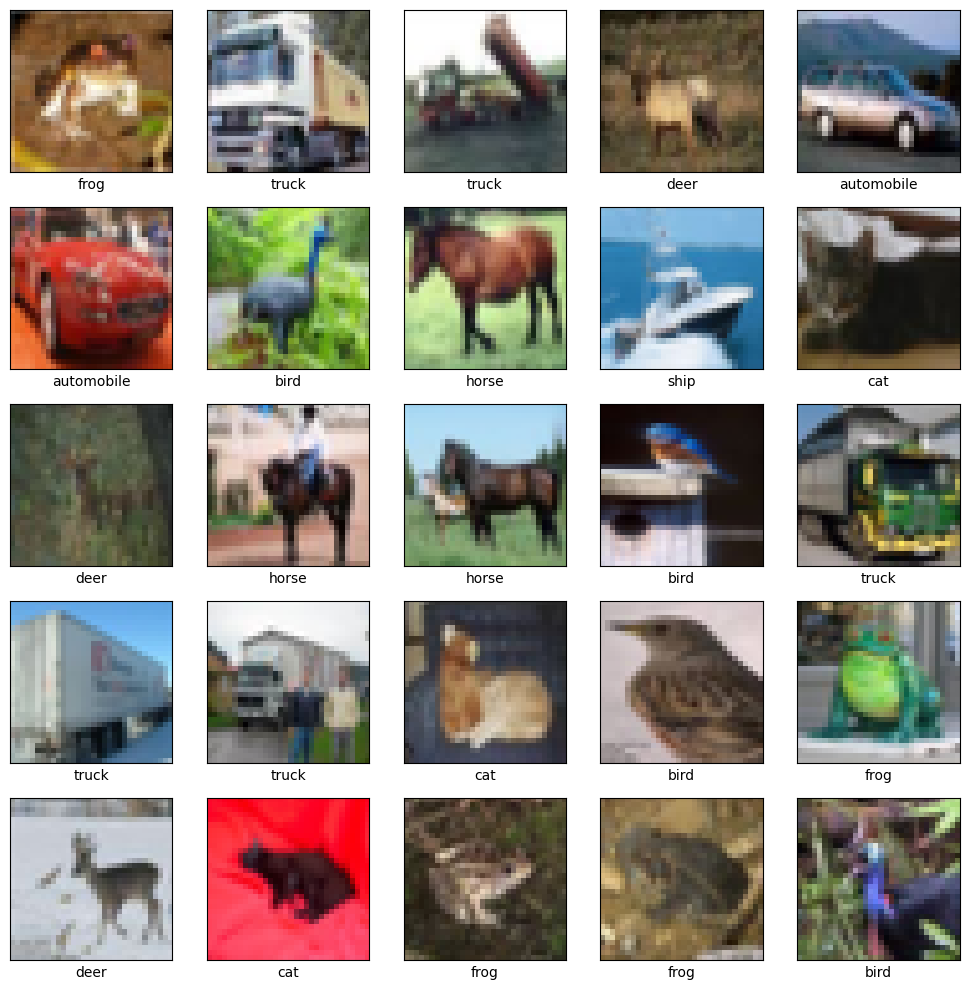

In [3]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i]])
plt.tight_layout()
plt.show()

In [4]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomZoom(0.10),
], name="data_augmentation")

In [5]:
def residual_block(x, filters, stride=1, dropout_rate=0.0):
    shortcut = x

    # Jalur utama
    x = layers.Conv2D(
        filters, kernel_size=3, strides=stride,
        padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)

    x = layers.Conv2D(
        filters, kernel_size=3, strides=1,
        padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)

    # Samakan dimensi shortcut jika ukuran atau jumlah channel berubah
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, kernel_size=1, strides=stride,
            padding="same", use_bias=False
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])
    x = layers.Activation("relu")(x)
    return x

In [6]:
inputs = layers.Input(shape=(32, 32, 3))

x = data_augmentation(inputs)

# Ekstraksi fitur awal
x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

# Residual stage 1: 32 filter
x = residual_block(x, 32)
x = residual_block(x, 32)

# Residual stage 2: 64 filter, ukuran feature map diperkecil
x = residual_block(x, 64, stride=2)
x = residual_block(x, 64)

# Residual stage 3: 128 filter
x = residual_block(x, 128, stride=2)
x = residual_block(x, 128)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(10, activation="softmax")(x)

model = models.Model(inputs=inputs, outputs=outputs, name="CNN_CIFAR10_Improved")
model.summary()

Model: "CNN_CIFAR10_Improved"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 32, 32, 3) │          0 │ input_layer[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │        864 │ data_augmentatio… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_3[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_4[0][0]  

 Total params: 715,370 (2.73 MB)

 Trainable params: 713,130 (2.72 MB)

 Non-trainable params: 2,240 (8.75 KB)

In [7]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [8]:
callback_list = [
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        "cifar10_cnn_terbaik.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

In [9]:
history = model.fit(
    train_images,
    train_labels,
    epochs=80,
    batch_size=64,
    validation_split=0.1,
    callbacks=callback_list,
    shuffle=True,
    verbose=1
)

Epoch 1/80
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2929 - loss: 1.9432
Epoch 1: val_accuracy improved from None to 0.30260, saving model to cifar10_cnn_terbaik.keras

Epoch 1: finished saving model to cifar10_cnn_terbaik.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 41s 40ms/step - accuracy: 0.3591 - loss: 1.7406 - val_accuracy: 0.3026 - val_loss: 3.1059 - learning_rate: 0.0010
Epoch 2/80
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.4800 - loss: 1.4324
Epoch 2: val_accuracy improved from 0.30260 to 0.50740, saving model to cifar10_cnn_terbaik.keras

Epoch 2: finished saving model to cifar10_cnn_terbaik.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.5039 - loss: 1.3714 - val_accuracy: 0.5074 - val_loss: 1.5190 - learning_rate: 0.0010
Epoch 3/80
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5590 - loss: 1.2451
Epoch 3: val_accuracy improved from 0.50740 to 0.56280, saving model to cifar10_cnn_terbaik.keras

Epoch 3: finished saving model to cifar

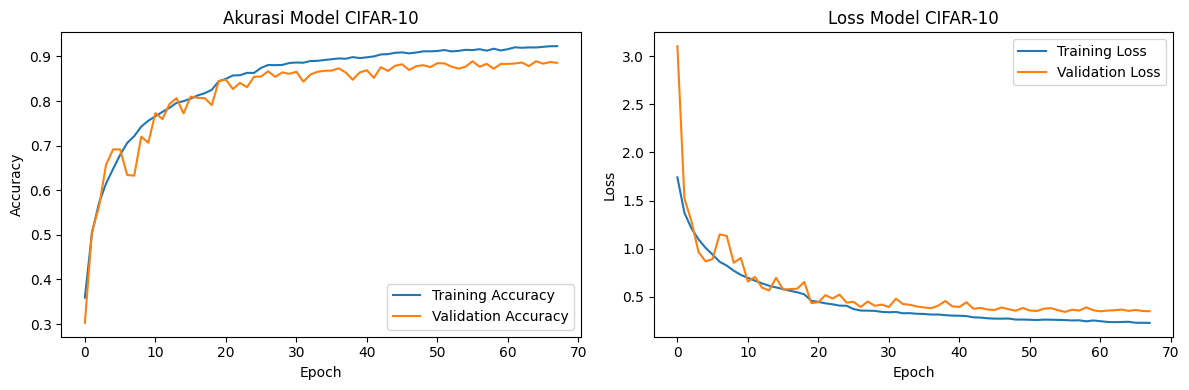

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Akurasi Model CIFAR-10")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Model CIFAR-10")
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)

print(f"Testing Loss     : {test_loss:.4f}")
print(f"Testing Accuracy : {test_acc * 100:.2f}%")

if test_acc > 0.80:
    print("Target tercapai: akurasi testing lebih dari 80%.")
else:
    print("Target belum tercapai. Coba jalankan ulang training atau tingkatkan epoch/penyetelan model.")

313/313 - 3s - 9ms/step - accuracy: 0.8860 - loss: 0.3642
Testing Loss     : 0.3642
Testing Accuracy : 88.60%
Target tercapai: akurasi testing lebih dari 80%.


79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step
              precision    recall  f1-score   support

    airplane       0.90      0.89      0.90      1000
  automobile       0.93      0.97      0.95      1000
        bird       0.85      0.85      0.85      1000
         cat       0.77      0.80      0.78      1000
        deer       0.88      0.88      0.88      1000
         dog       0.86      0.78      0.82      1000
        frog       0.86      0.95      0.91      1000
       horse       0.92      0.90      0.91      1000
        ship       0.96      0.91      0.93      1000
       truck       0.93      0.92      0.93      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



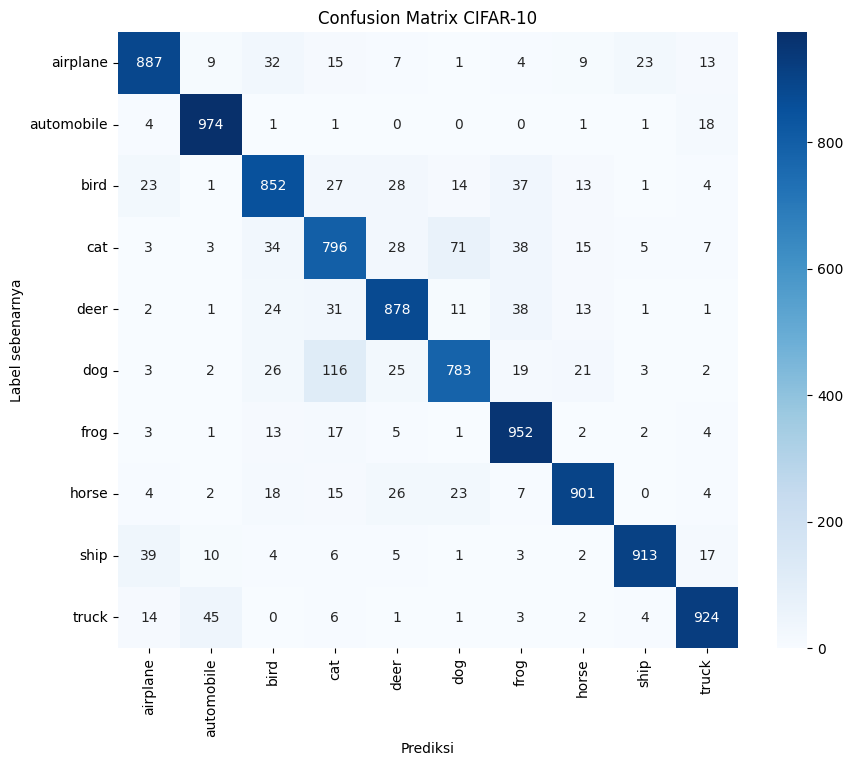

In [12]:
pred_prob = model.predict(test_images, batch_size=128)
pred_labels = np.argmax(pred_prob, axis=1)

print(classification_report(
    test_labels,
    pred_labels,
    target_names=class_names
))

cm = confusion_matrix(test_labels, pred_labels)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Prediksi")
plt.ylabel("Label sebenarnya")
plt.title("Confusion Matrix CIFAR-10")
plt.show()

In [13]:
model.save("model_cnn_cifar10.keras")
print("Model CIFAR-10 berhasil disimpan.")

Model CIFAR-10 berhasil disimpan.


In [14]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import datasets, layers, models

(train_mnist, train_mnist_labels), (test_mnist, test_mnist_labels) = datasets.mnist.load_data()

print("Shape training:", train_mnist.shape)
print("Shape testing :", test_mnist.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shape training: (60000, 28, 28)
Shape testing : (10000, 28, 28)


In [15]:
train_mnist = train_mnist.astype("float32") / 255.0
test_mnist = test_mnist.astype("float32") / 255.0

train_mnist = np.expand_dims(train_mnist, axis=-1)
test_mnist = np.expand_dims(test_mnist, axis=-1)

print("Shape setelah preprocessing:", train_mnist.shape)

Shape setelah preprocessing: (60000, 28, 28, 1)


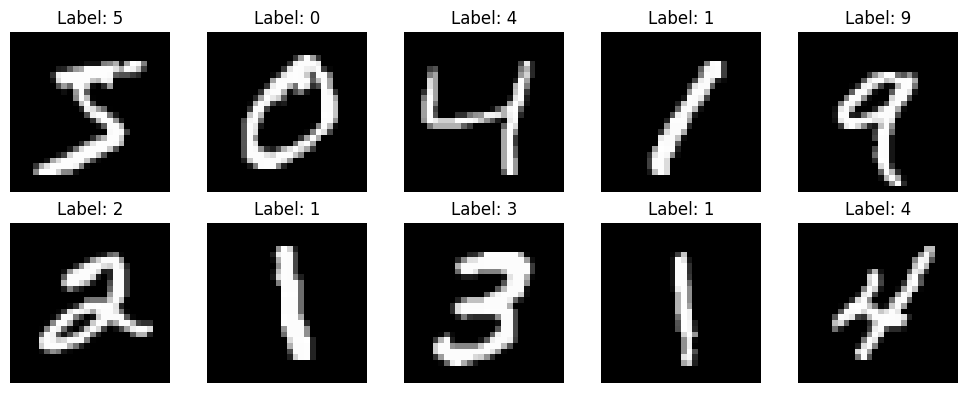

In [16]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(train_mnist[i].squeeze(), cmap="gray")
    plt.title(f"Label: {train_mnist_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [17]:
mnist_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(10, activation="softmax")
])

mnist_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
mnist_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [19]:
mnist_history = mnist_model.fit(
    train_mnist,
    train_mnist_labels,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.9190 - loss: 0.2648 - val_accuracy: 0.9840 - val_loss: 0.0562
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9781 - loss: 0.0711 - val_accuracy: 0.9868 - val_loss: 0.0458
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9838 - loss: 0.0520 - val_accuracy: 0.9897 - val_loss: 0.0400
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9867 - loss: 0.0418 - val_accuracy: 0.9912 - val_loss: 0.0336
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9890 - loss: 0.0340 - val_accuracy: 0.9908 - val_loss: 0.0325
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9910 - loss: 0.0287 - val_accuracy: 0.9910 - val_loss: 0.0331
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9924 - loss: 0.0246 - val_accuracy: 0.9895 - val_loss: 0.0399
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9933 - loss: 0.0218 - val_accuracy: 

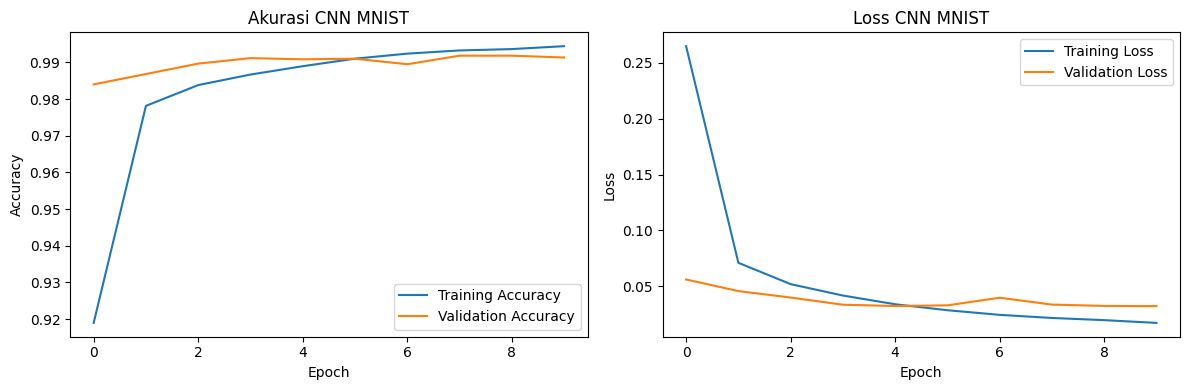

In [20]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(mnist_history.history["accuracy"], label="Training Accuracy")
plt.plot(mnist_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Akurasi CNN MNIST")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(mnist_history.history["loss"], label="Training Loss")
plt.plot(mnist_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss CNN MNIST")
plt.legend()

plt.tight_layout()
plt.show()

In [21]:
mnist_test_loss, mnist_test_acc = mnist_model.evaluate(
    test_mnist, test_mnist_labels, verbose=2
)

print(f"MNIST Testing Loss     : {mnist_test_loss:.4f}")
print(f"MNIST Testing Accuracy : {mnist_test_acc * 100:.2f}%")

313/313 - 5s - 14ms/step - accuracy: 0.9922 - loss: 0.0243
MNIST Testing Loss     : 0.0243
MNIST Testing Accuracy : 99.22%


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


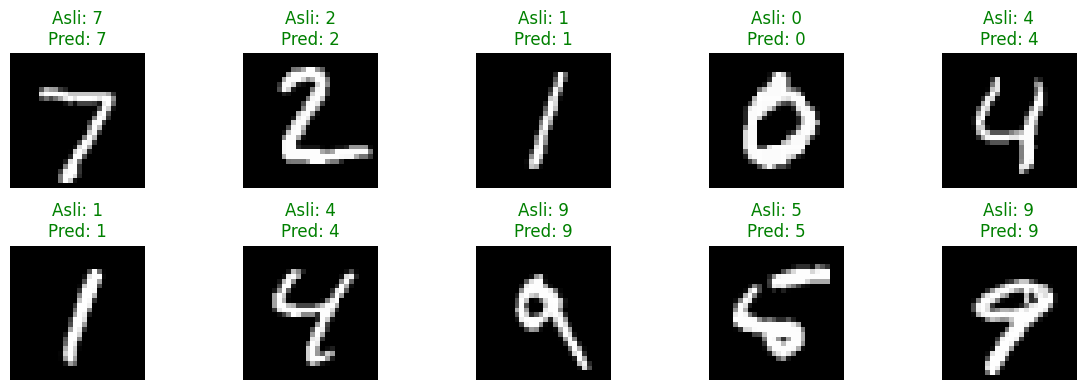

In [22]:
sample_images = test_mnist[:10]
sample_labels = test_mnist_labels[:10]

predictions = mnist_model.predict(sample_images)
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(sample_images[i].squeeze(), cmap="gray")
    color = "green" if predicted_labels[i] == sample_labels[i] else "red"
    plt.title(
        f"Asli: {sample_labels[i]}\nPred: {predicted_labels[i]}",
        color=color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
mnist_model.save("model_cnn_mnist.keras")
print("Model MNIST berhasil disimpan.")

Model MNIST berhasil disimpan.
